# PCD Assignment 03: Image Segmentation and Morphological Processing

* **Nama:** Muhammad Gauza Faliha
* **NIM:** 25/555851/PA/23315
* **Prodi:** Ilmu Komputer
* **Mata Kuliah:** Pengolahan Citra Digital

Pada notebook ini saya mengimplementasikan metode segmentasi citra menggunakan Otsu Thresholding dan operasi morfologi yang mencakup Erosi, Dilasi, Opening, dan Closing (tanpa lib) pada citra sidik jari, kemudian membandingkan hasil dari segmentasi before and after pada penerapan pemrosesan morfologi.

## Inisialisasi Modul

Pertama yang pasti saya akan mengimprort/memuat beberapa modul yang diperlukan terlebih dahulu. Di sini saya menggunakan NumPy untuk komputasi array matriks, PIL Image untuk membaca citra dari lokal, Matplotlib untuk menampilkan visualisasi grafik serta perbandingan citra, dan collections deque untuk penelusuran antrean pada evaluasi komponen terhubung.

In [12]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from collections import deque

print("Modul berhasil diimport")

Modul berhasil diimport


## Import Citra dan Konversi Keabuan/Grayscale

Pada tahap kedua, saya mengimport dan membaca citra sidik jari 100__M_Left_index_finger.bmp (96 x 103 piksel), lalu memastikannya dalam satu kanal keabuan. Kalau masukan berupa RGB, saya konversi manual dengan bobot NTSC Y = 0.299 R + 0.587 G + 0.114 B. Alur sidik jari berwarna gelap dan latar belakangnya terang.

Pada tepi atas dan kiri citra terdapat bingkai abu-abu setebal 2 piksel yang bukan bagian dari sidik jari. Bingkai ini akan ikut tersegmentasi sebagai objek, menggeser nilai T Otsu, dan ikut terhitung sebagai komponen. Karena itu bingkai tersebut saya buang (crop) sebelum citra diproses.

In [13]:
import os

def load_grayscale_image(file_path):
    raw_img = Image.open(file_path)
    img_array = np.array(raw_img)
    if len(img_array.shape) == 3:
        r = img_array[:, :, 0].astype(np.float64)
        g = img_array[:, :, 1].astype(np.float64)
        b = img_array[:, :, 2].astype(np.float64)
        gray_array = 0.299 * r + 0.587 * g + 0.114 * b
        return gray_array.astype(np.uint8)
    return img_array.astype(np.uint8)

image_path = "100__M_Left_index_finger.bmp"
if not os.path.exists(image_path):
    image_path = "100__M_Left_index_finger.jpg"
full_image = load_grayscale_image(image_path)
print(f"Dimensi citra asli: {full_image.shape[1]} x {full_image.shape[0]} piksel")

# bingkai abu-abu 2 piksel di sisi atas dan kiri bukan bagian sidik jari
FRAME = 2
gray_image = full_image[FRAME:, FRAME:]
height, width = gray_image.shape

print(f"Dimensi setelah crop bingkai: {width} x {height} piksel")
print(f"Total piksel: {height * width}")
print(f"Rentang intensitas: {np.min(gray_image)} sampai {np.max(gray_image)}")

Dimensi citra asli: 96 x 103 piksel
Dimensi setelah crop bingkai: 94 x 101 piksel
Total piksel: 9494
Rentang intensitas: 0 sampai 255


## Perhitungan Histogram Citra

Langkah berikutnya saya menghitung histogram frekuensi intensitas piksel 0 sampai 255 dengan looping. Histogramnya tidak bimodal, hampir semua piksel latar belakang menumpuk di sekitar 250 sampai 255, sedangkan alur sidik jari tersebar landai di intensitas rendah sampai menengah. Distribusi seperti ini tetap bisa ditangani Otsu, tapi ambang batas yang didapat nanti lebih tepat dibaca sebagai pemisah yang cukup rasional secara global. 

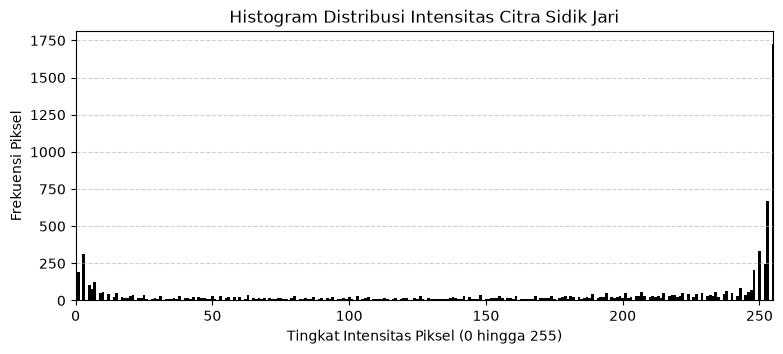

In [14]:
def compute_histogram(gray_img):
    h, w = gray_img.shape
    hist = np.zeros(256, dtype=np.int64)
    for r in range(h):
        for c in range(w):
            intensity = gray_img[r, c]
            hist[intensity] += 1
    return hist

hist_data = compute_histogram(gray_image)

plt.figure(figsize=(9, 3.5))
plt.bar(range(256), hist_data, color="black", width=1.0)
plt.title("Histogram Distribusi Intensitas Citra Sidik Jari")
plt.xlabel("Tingkat Intensitas Piksel (0 hingga 255)")
plt.ylabel("Frekuensi Piksel")
plt.xlim([0, 255])
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

## Segmentasi Citra Menggunakan Metode Otsu

Lalu, pada bagian ini saya menerapkan segmentasi citra menggunakan metode Otsu Thresholding. Algoritma ini mencari nilai ambang batas T optimal secara otomatis dengan menguji seluruh kandidat nilai intensitas dan memilih nilai T yang menghasilkan Within Class Variance terendah. Kemudian setelah nilai T optimal ditemukan, saya melakukan binerisasi dengan membalik nilai polaritas agar alur alur sidik jari ditetapkan bernilai satu sebagai objek utama dan latar belakang bernilai nol.

Nilai ambang batas optimal Otsu: T = 128


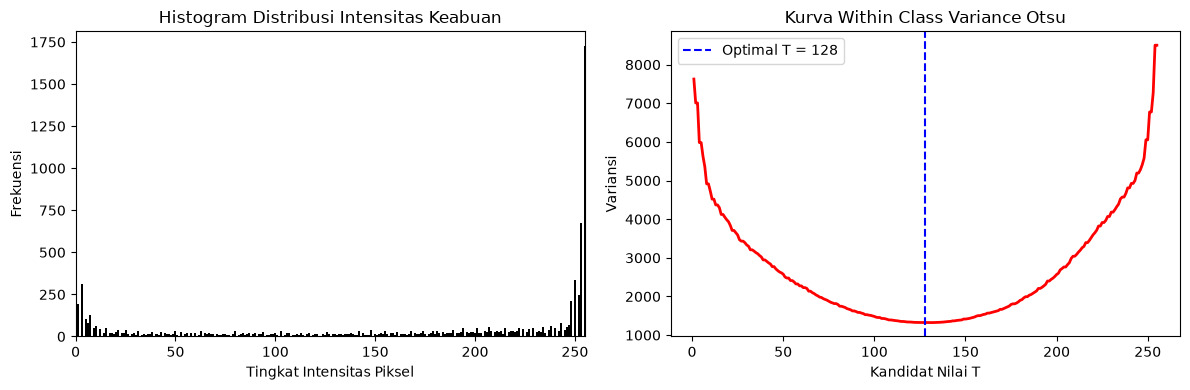

In [15]:
def otsu_thresholding_scratch(gray_img):
    h, w = gray_img.shape
    total_pixels = h * w
    hist = compute_histogram(gray_img)
    prob = hist / total_pixels
    
    min_within_variance = float("inf")
    optimal_threshold = 0
    variance_curve = np.zeros(256, dtype=np.float64)
    
    for t in range(256):
        w0 = np.sum(prob[:t])
        w1 = np.sum(prob[t:])
        
        if w0 == 0 or w1 == 0:
            variance_curve[t] = np.nan
            continue
            
        intensities_0 = np.arange(t)
        intensities_1 = np.arange(t, 256)
        
        mu0 = np.sum(intensities_0 * prob[:t]) / w0
        mu1 = np.sum(intensities_1 * prob[t:]) / w1
        
        var0 = np.sum(((intensities_0 - mu0) ** 2) * prob[:t]) / w0
        var1 = np.sum(((intensities_1 - mu1) ** 2) * prob[t:]) / w1
        
        within_variance = w0 * var0 + w1 * var1
        variance_curve[t] = within_variance
        
        if within_variance < min_within_variance:
            min_within_variance = within_variance
            optimal_threshold = t
            
    binary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if gray_img[r, c] < optimal_threshold:
                binary_img[r, c] = 1
            else:
                binary_img[r, c] = 0
                
    return optimal_threshold, binary_img, variance_curve

optimal_t, raw_segmented, var_history = otsu_thresholding_scratch(gray_image)
print(f"Nilai ambang batas optimal Otsu: T = {optimal_t}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.bar(range(256), hist_data, color="black", width=1.0)
plt.title("Histogram Distribusi Intensitas Keabuan")
plt.xlabel("Tingkat Intensitas Piksel")
plt.ylabel("Frekuensi")
plt.xlim([0, 255])

plt.subplot(1, 2, 2)
plt.plot(range(256), var_history, color="red", linewidth=2)
plt.axvline(x=optimal_t, color="blue", linestyle="--", label=f"Optimal T = {optimal_t}")
plt.title("Kurva Within Class Variance Otsu")
plt.xlabel("Kandidat Nilai T")
plt.ylabel("Variansi")
plt.legend()

plt.tight_layout()
plt.savefig("analisis_otsu_histogram.png", dpi=200)
plt.show()

## Analisis Hasil Segmentasi Tanpa Morfologi

Di sini saya menampilkan citra biner mentah hasil Otsu sebagai baseline tanpa morfologi. Karena Otsu hanya melihat nilai keabuan/grayscale tiap piksel, hasilnya masih punya tiga masalah, yaitu alur yang terputus-putus, lubang kecil (pori) di dalam alur, dan bintik kecil di latar belakang. Selain itu di bagian bawah tengah citra alur-alurnya menyatu karena area itu memang lebih gelap, jadi satu ambang batas global kurang pas di sana.

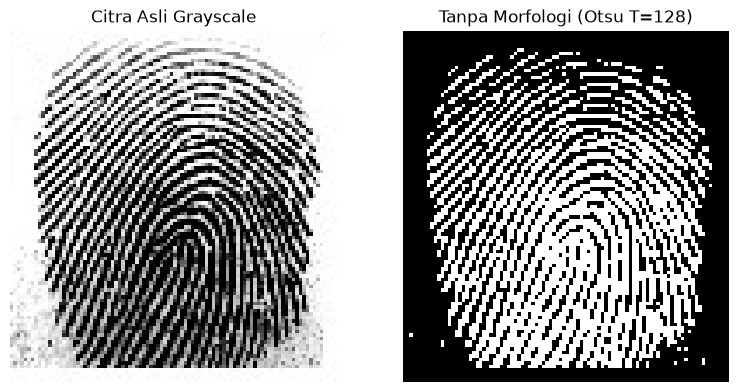

In [16]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.title("Citra Asli Grayscale")
plt.imshow(gray_image, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title(f"Tanpa Morfologi (Otsu T={optimal_t})")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

## Implementasi Operator Morfologi

Untuk memperbaiki hasil biner tersebut, saya mengimplementasikan zero padding dan basic operation dari morfologi :
* Erosi: piksel keluaran bernilai satu hanya jika seluruh elemen penstruktur tepat berada di atas piksel objek.
* Dilasi: piksel keluaran bernilai satu jika minimal satu elemen penstruktur mengenai piksel objek.
* Opening: erosi lalu dilasi, menghapus objek kecil.
* Closing: dilasi lalu erosi, menutup celah dan lubang kecil.
* Ekstraksi kontur: citra biner dikurangi hasil erosinya.
* Penghapusan komponen kecil (area opening): tambahan saya, komponen dengan jumlah piksel di bawah batas tertentu dihapus. Fungsi ini memakai penelusuran BFS yang sama dengan evaluasi di bagian akhir.

Elemen penstruktur harus ukuran ganjil karena titik asal (origin) diletakkan di tengah.

In [17]:
def manual_pad_image(binary_img, pad_h, pad_w):
    h, w = binary_img.shape
    padded = np.zeros((h + 2 * pad_h, w + 2 * pad_w), dtype=np.uint8)
    padded[pad_h:h + pad_h, pad_w:w + pad_w] = binary_img
    return padded

def morphological_erosion(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    eroded = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.all(sub_window[active_mask] == 1):
                eroded[r, c] = 1
    return eroded

def morphological_dilation(binary_img, structuring_element):
    h, w = binary_img.shape
    se_h, se_w = structuring_element.shape
    pad_h = se_h // 2
    pad_w = se_w // 2
    
    padded = manual_pad_image(binary_img, pad_h, pad_w)
    dilated = np.zeros((h, w), dtype=np.uint8)
    active_mask = (structuring_element == 1)
    
    for r in range(h):
        for c in range(w):
            sub_window = padded[r:r + se_h, c:c + se_w]
            if np.any(sub_window[active_mask] == 1):
                dilated[r, c] = 1
    return dilated

def morphological_opening(binary_img, structuring_element):
    return morphological_dilation(morphological_erosion(binary_img, structuring_element), structuring_element)

def morphological_closing(binary_img, structuring_element):
    return morphological_erosion(morphological_dilation(binary_img, structuring_element), structuring_element)

def morphological_boundary(binary_img, structuring_element):
    eroded = morphological_erosion(binary_img, structuring_element)
    h, w = binary_img.shape
    boundary_img = np.zeros((h, w), dtype=np.uint8)
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and eroded[r, c] == 0:
                boundary_img[r, c] = 1
    return boundary_img

def connected_components_scratch(binary_img, connectivity=8):
    """BFS dari nol. Mengembalikan daftar komponen, tiap komponen berisi list koordinat piksel."""
    h, w = binary_img.shape
    visited = np.zeros((h, w), dtype=bool)
    if connectivity == 8:
        offsets = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        offsets = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    components = []
    for r in range(h):
        for c in range(w):
            if binary_img[r, c] == 1 and not visited[r, c]:
                queue = deque([(r, c)])
                visited[r, c] = True
                pixels = []
                while queue:
                    cr, cc = queue.popleft()
                    pixels.append((cr, cc))
                    for dr, dc in offsets:
                        nr, nc = cr + dr, cc + dc
                        if 0 <= nr < h and 0 <= nc < w:
                            if binary_img[nr, nc] == 1 and not visited[nr, nc]:
                                visited[nr, nc] = True
                                queue.append((nr, nc))
                components.append(pixels)
    return components

def remove_small_components(binary_img, min_size, connectivity=8):
    result = np.zeros_like(binary_img)
    for pixels in connected_components_scratch(binary_img, connectivity):
        if len(pixels) >= min_size:
            for (r, c) in pixels:
                result[r, c] = 1
    return result

print("Operator morfologi berhasil diimplementasikan.")

Operator morfologi berhasil diimplementasikan.


## Penerapan Operasi Morfologi Pada Citra Sidik Jari

Operasi morfologi saya terapkan dengan dua cara/metode. Cara pertama adalah operator tunggal dengan elemen penstruktur kernel 3x3 (panel 3 sampai 6), untuk melihat pengaruh tiap operator pada citra. Cara kedua adalah pipeline yang saya pilih sebagai hasil akhir.

Pada citra ini lebar celah antar alur sekitar 2 piksel dan ketebalan alurnya 2 sampai 3 piksel. Karena itu closing 3x3 menjembatani celah antar alur sehingga seluruh area sidik jari menjadi blok putih utuh. Erosi dan opening dengan elemen yang sama membuang lebih dari separuh piksel alur. Operator tunggal 3x3 jadi tidak saya pakai sebagai hasil akhir.

Pipeline/ALur yang saya pilih terdiri dari tiga langkah:
1. Closing lalu opening dengan elemen kotak 7x7 untuk membentuk *mask* daerah sidik jari (ROI).
2. Mask tersebut dikalikan (AND) dengan citra biner mentah, sehingga bintik di luar sidik jari hilang dan alur di dalamnya tidak berubah.
3. Komponen kecil di bawah 6 piksel dihapus.

In [ ]:
se_cross = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)
se_square3 = np.ones((3, 3), dtype=np.uint8)
se_roi = np.ones((7, 7), dtype=np.uint8)

print("Elemen Penstruktur Palang:")
print(se_cross)

# operator tunggal dengan SE Kernel 3x3
eroded_result = morphological_erosion(raw_segmented, se_cross)
dilated_result = morphological_dilation(raw_segmented, se_cross)
opened_result = morphological_opening(raw_segmented, se_cross)
closed_result = morphological_closing(raw_segmented, se_cross)

# pipeline: bentuk mask ROI dengan SE besar, lalu AND dengan citra mentah
roi_mask = morphological_closing(raw_segmented, se_roi)
roi_mask = morphological_opening(roi_mask, se_roi)
roi_mask = remove_small_components(roi_mask, min_size=200)
masked_result = raw_segmented & roi_mask
enhanced_pipeline = remove_small_components(masked_result, min_size=6)

# kontur diambil dari hasil pipeline, bukan dari citra mentah
boundary_result = morphological_boundary(enhanced_pipeline, se_cross)

print("Operasi morfologi selesai dijalankan.")

Elemen Penstruktur Palang:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Operasi morfologi selesai dijalankan.


## Evaluasi Kuantitatif

Untuk membandingkan hasil sebelum dan sesudah morfologi, saya memakai tiga ukuran yang dihitung dari nol:

* **Jumlah komponen terhubung** dengan penelusuran BFS. Konektivitas-8 menjadi ukuran utama karena alur sidik jari pada citra ini miring. Pada konektivitas-4, garis diagonal tipis terhitung putus di setiap anak tangga piksel, sehingga jumlah komponennya membengkak. Konektivitas-4 tetap saya tampilkan sebagai pembanding.
* **Jumlah komponen kecil** (kurang dari 6 piksel), sebagai ukuran bintik kotoran.
* **Rasio piksel objek di dalam ROI**, yaitu persentase piksel bernilai satu di dalam area sidik jari. Ukuran ini menunjukkan apakah celah antar alur masih terjaga. Jika angkanya mendekati 100 persen, berarti celah antar alur sudah tertutup dan alur menyatu menjadi blok.

Jumlah komponen saja tidak cukup, karena angkanya bisa turun hanya akibat alur-alur yang menyatu, bukan karena alur yang putus tersambung dengan benar. Karena itu rasio ROI saya pakai bersama jumlah komponen.

In [19]:
def evaluate(name, img):
    comps8 = connected_components_scratch(img, connectivity=8)
    comps4 = connected_components_scratch(img, connectivity=4)
    small = sum(1 for p in comps8 if len(p) < 6)
    roi_ratio = 100.0 * img[roi_mask == 1].sum() / roi_mask.sum()
    return {"nama": name, "cc4": len(comps4), "cc8": len(comps8),
            "kecil": small, "piksel": int(img.sum()), "rasio_roi": roi_ratio}

stages = [
    ("Otsu mentah", raw_segmented),
    ("Closing palang 3x3", closed_result),
    ("Opening palang 3x3", opened_result),
    ("Pipeline mask ROI + hapus bintik", enhanced_pipeline),
]
results = [evaluate(n, im) for n, im in stages]

print(f"{'Tahap':36s}{'CC-4':>6s}{'CC-8':>6s}{'<6px':>6s}{'Piksel':>8s}{'Rasio ROI':>11s}")
for r in results:
    print(f"{r['nama']:36s}{r['cc4']:6d}{r['cc8']:6d}{r['kecil']:6d}{r['piksel']:8d}{r['rasio_roi']:10.1f}%")

comp_before = results[0]["cc8"]
comp_after_closing = results[1]["cc8"]
comp_after_pipeline = results[3]["cc8"]

Tahap                                 CC-4  CC-8  <6px  Piksel  Rasio ROI
Otsu mentah                            166    43    23    3717      57.0%
Closing palang 3x3                      48    16    15    5806      89.0%
Opening palang 3x3                      76    39    18    1748      26.9%
Pipeline mask ROI + hapus bintik       136    20     0    3670      56.4%


## Visualisasi dan Perbandingan 

Pada bagian ini saya menampilkan perbandingan visual menyeluruh delapan panel secara berdampingan. Di sini kita dapat melihat secara jelas bagaimana citra asli bertransformasi menjadi citra biner mentah yang terputus putus, kemudian diperbaiki oleh operasi Closing yang menyambungkan kembali alur alur dan menutup lubang pori, serta disempurnakan oleh pipeline kombinasi yang menghasilkan alur sidik jari kontinu dengan latar belakang yang bersih.

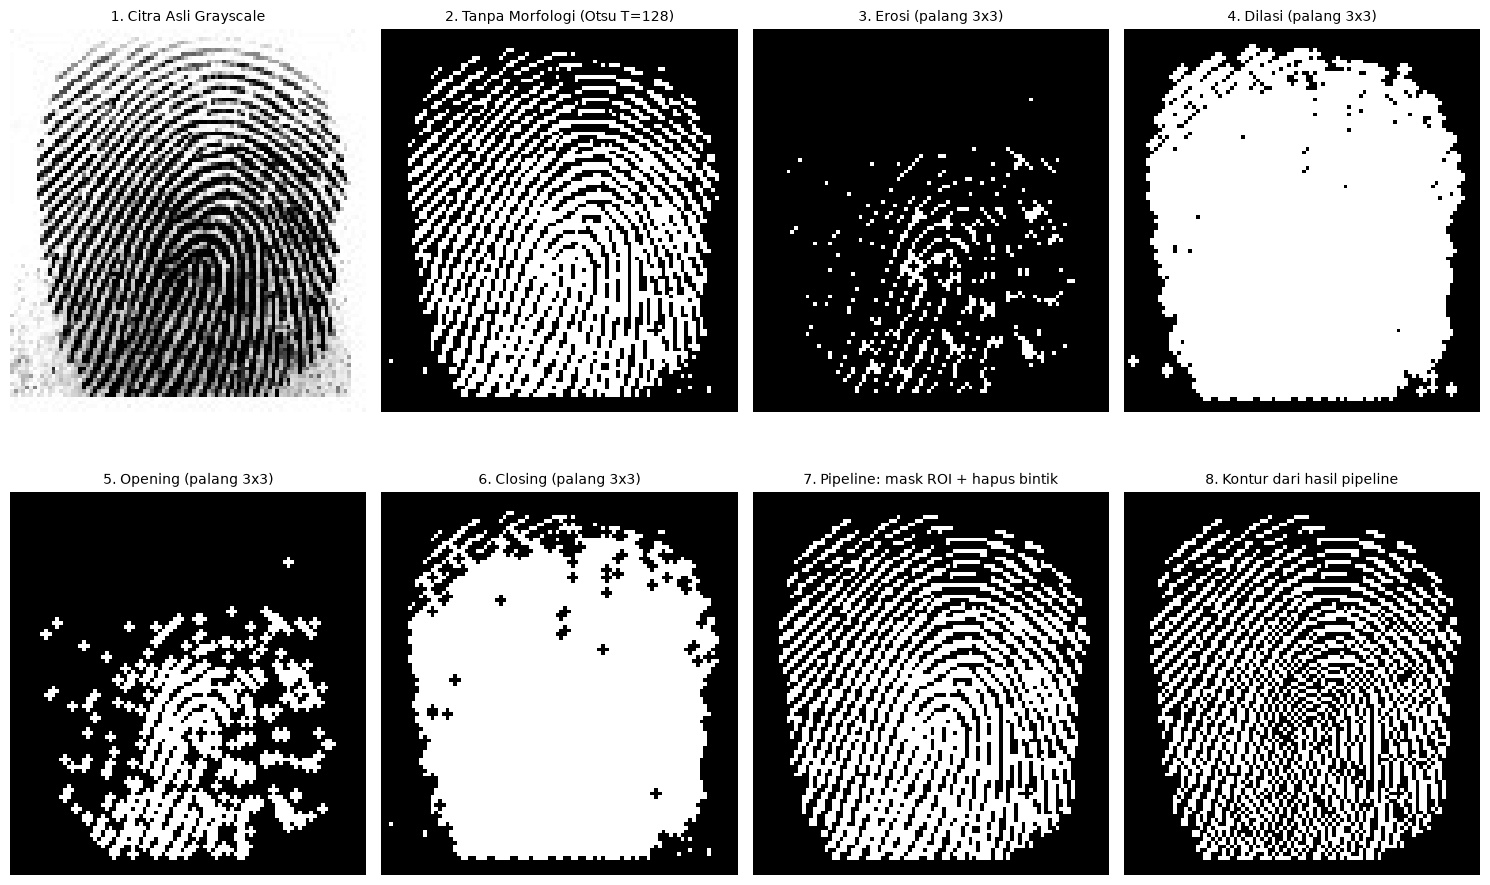

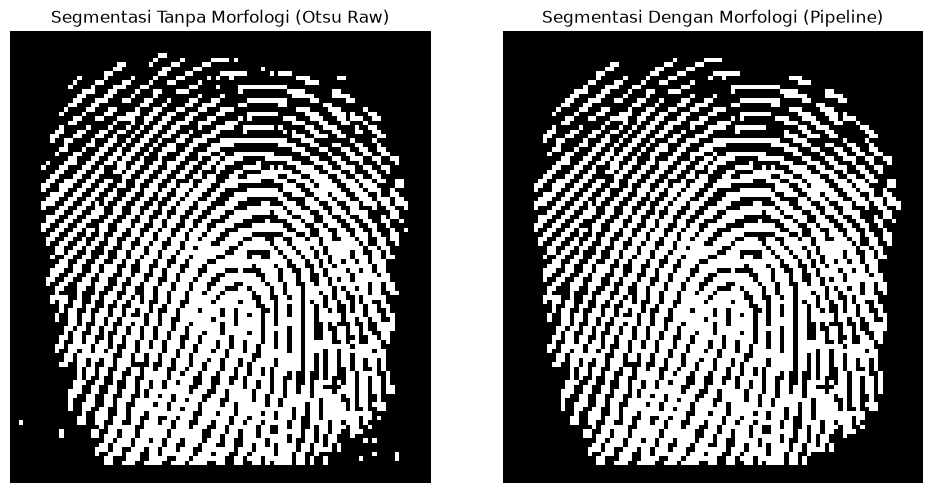

In [20]:
plt.figure(figsize=(15, 10))

panels = [
    ("1. Citra Asli Grayscale", gray_image),
    (f"2. Tanpa Morfologi (Otsu T={optimal_t})", raw_segmented),
    ("3. Erosi (palang 3x3)", eroded_result),
    ("4. Dilasi (palang 3x3)", dilated_result),
    ("5. Opening (palang 3x3)", opened_result),
    ("6. Closing (palang 3x3)", closed_result),
    ("7. Pipeline: mask ROI + hapus bintik", enhanced_pipeline),
    ("8. Kontur dari hasil pipeline", boundary_result),
]
for i, (title, im) in enumerate(panels, start=1):
    plt.subplot(2, 4, i)
    plt.title(title, fontsize=10)
    plt.imshow(im, cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil_perbandingan_lengkap.png", dpi=200)
plt.show()

# perbandingan sebelum vs sesudah (pipeline terpilih)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Segmentasi Tanpa Morfologi (Otsu Raw)")
plt.imshow(raw_segmented, cmap="gray")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.title("Segmentasi Dengan Morfologi (Pipeline)")
plt.imshow(enhanced_pipeline, cmap="gray")
plt.axis("off")
plt.tight_layout()
plt.savefig("hasil_sebelum_dan_sesudah.png", dpi=200)
plt.show()

## Pengaruh Ukuran dan Bentuk Elemen Penstruktur

Di sini saya coba closing dengan beberapa elemen penstruktur yang berbeda, lalu saya lihat rasio piksel objek di dalam ROI-nya. Hasil yang bagus adalah yang rasionya tidak jauh dari citra mentah. Kalau rasionya naik sampai hampir 100 persen, berarti celah antar alur sudah tertutup semua.

In [21]:
se_candidates = {
    "garis horizontal 1x3": np.array([[1, 1, 1]], dtype=np.uint8),
    "garis vertikal 3x1": np.array([[1], [1], [1]], dtype=np.uint8),
    "palang 3x3": se_cross,
    "kotak 3x3": se_square3,
}
raw_ratio = 100.0 * raw_segmented[roi_mask == 1].sum() / roi_mask.sum()
print(f"Citra mentah: rasio objek di ROI = {raw_ratio:.1f}%\n")
for name, se in se_candidates.items():
    res = morphological_closing(raw_segmented, se)
    ratio = 100.0 * res[roi_mask == 1].sum() / roi_mask.sum()
    n8 = len(connected_components_scratch(res, 8))
    print(f"Closing {name:22s} -> rasio ROI {ratio:5.1f}% | CC-8 = {n8}")

Citra mentah: rasio objek di ROI = 57.0%

Closing garis horizontal 1x3   -> rasio ROI  81.9% | CC-8 = 26
Closing garis vertikal 3x1     -> rasio ROI  77.7% | CC-8 = 11
Closing palang 3x3             -> rasio ROI  89.0% | CC-8 = 16
Closing kotak 3x3              -> rasio ROI  96.2% | CC-8 = 6


In [22]:
r0, r1, r2, r3 = results
print("Ringkasan angka (dibuat otomatis dari hasil di atas):")
print(f"- Nilai ambang Otsu: T = {optimal_t}")
print(f"- Komponen CC-8: mentah {r0['cc8']} -> closing palang {r1['cc8']} -> pipeline {r3['cc8']}")
print(f"- Komponen CC-4: mentah {r0['cc4']} -> pipeline {r3['cc4']}")
print(f"- Komponen kecil (<6 px): mentah {r0['kecil']} -> pipeline {r3['kecil']}")
print(f"- Rasio objek di ROI: mentah {r0['rasio_roi']:.1f}%, closing palang {r1['rasio_roi']:.1f}%, pipeline {r3['rasio_roi']:.1f}%")
print(f"- Piksel alur: mentah {r0['piksel']}, pipeline {r3['piksel']} (selisih {100*(r0['piksel']-r3['piksel'])/r0['piksel']:.1f}%)")

Ringkasan angka (dibuat otomatis dari hasil di atas):
- Nilai ambang Otsu: T = 128
- Komponen CC-8: mentah 43 -> closing palang 16 -> pipeline 20
- Komponen CC-4: mentah 166 -> pipeline 136
- Komponen kecil (<6 px): mentah 23 -> pipeline 0
- Rasio objek di ROI: mentah 57.0%, closing palang 89.0%, pipeline 56.4%
- Piksel alur: mentah 3717, pipeline 3670 (selisih 1.3%)


## Kesimpulan

1. **Otsu** dapat memisahkan alur sidik jari dari latar belakang secara otomatis dengan T = 128. Tapi hasil mentahnya masih punya alur yang putus-putus dan bintik di latar. Bagian bawah citra juga masih menyatu karena threshold-nya satu untuk seluruh citra.

2. **Operator tunggal 3x3 palang/kernel kurang cocok** untuk citra ini, karena alur dan celahnya cuma selebar 2 sampai 3 piksel. Erosi dan opening membuang lebih dari separuh piksel alur, sedangkan dilasi dan closing menutup celah antar alur sampai area sidik jari jadi blok putih. Jumlah komponen pada closing memang turun, tapi itu karena alurnya menyatu, bukan karena alur yang putus tersambung.

3. **Pipeline mask ROI** hasilnya paling bagus. Mask dibentuk dengan closing dan opening kotak 7x7, di-AND dengan citra mentah, lalu komponen kecil dihapus. Bintik di luar sidik jari hilang dan rasio alur di dalam ROI hampir sama dengan citra mentah, jadi bentuk alurnya tetap terjaga. Di sini morfologi dipakai untuk menemukan daerah sidik jari, bukan untuk mengubah alurnya.

4. **Keterbatasan:** pipeline ini belum menyambung alur yang putus di dalam sidik jari dan belum memperbaiki bagian bawah yang menyatu. Kemungkinan perbaikannya adalah thresholding lokal (misalnya Otsu per blok), namun hal tersebut belum saya lakukan pada tugas ini karena tugas hanya meminta satu metode segmentasi dan beberapa operasi morfologi, sehingga thresholding lokal berada di luar cakupan.